<a href="https://colab.research.google.com/github/Nabilah1998/Graphics-Gesign-Image-processing/blob/main/GDIP_lab_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving Dew-Kissed Red Rose in Bloom.png to Dew-Kissed Red Rose in Bloom.png


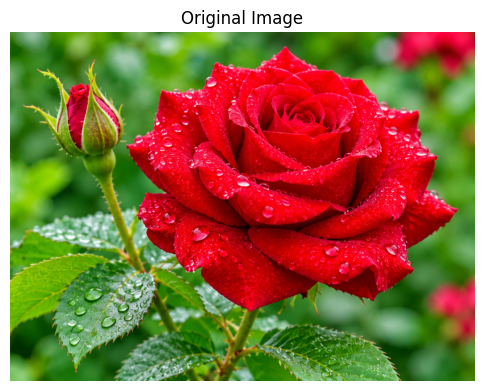

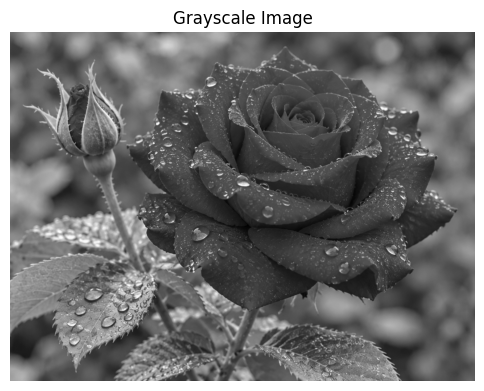

Saving Dew-Kissed Red Rose in Bloom.png to Dew-Kissed Red Rose in Bloom (1).png


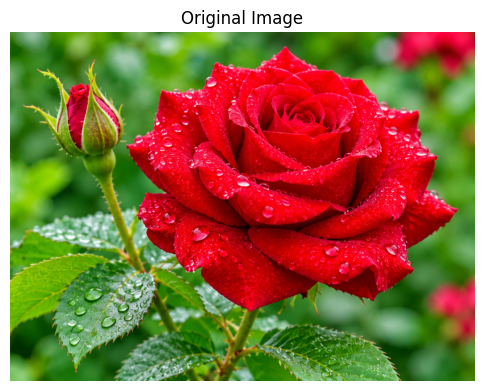

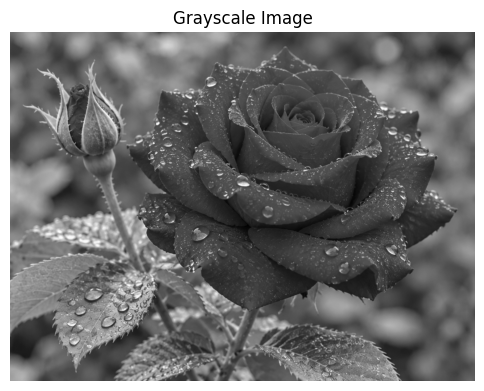

In [4]:
#Import Libraries and Upload Image
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
import os

%matplotlib inline

# Upload image
uploaded = files.upload()

# Read uploaded image
image_name = list(uploaded.keys())[0]

img = cv2.imdecode(
    np.frombuffer(uploaded[image_name], np.uint8),
    cv2.IMREAD_COLOR
)

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Display original image
plt.figure(figsize=(6,5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.show()

# Display grayscale image
plt.figure(figsize=(6,5))
plt.imshow(gray, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

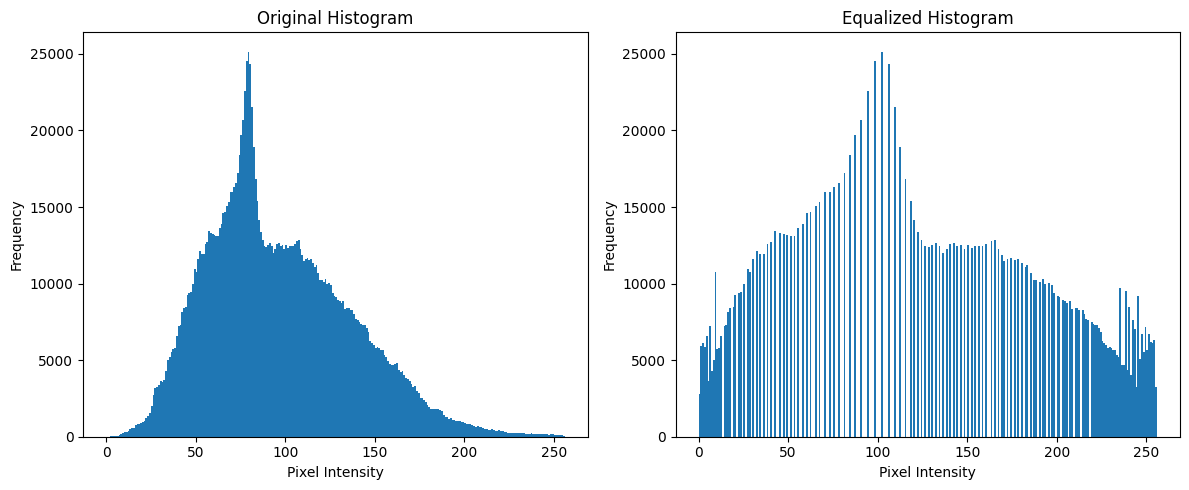

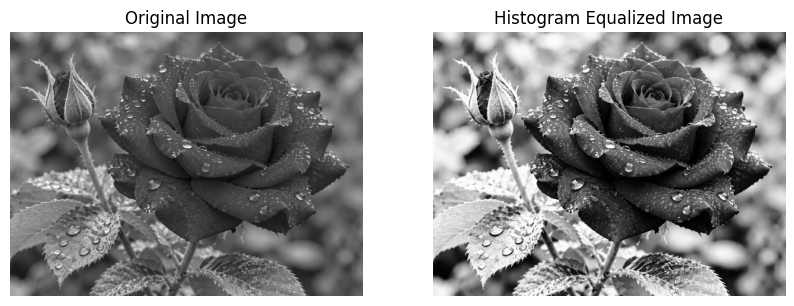

In [5]:
#Histogram Equalization and Histogram Equalizer
# Calculate original histogram
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.hist(gray.ravel(), bins=256, range=[0,256])
plt.title("Original Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

# Apply histogram equalization
equalized = cv2.equalizeHist(gray)

# Calculate equalized histogram
plt.subplot(1,2,2)
plt.hist(equalized.ravel(), bins=256, range=[0,256])
plt.title("Equalized Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

# Display images
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(gray, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(equalized, cmap='gray')
plt.title("Histogram Equalized Image")
plt.axis("off")

plt.show()

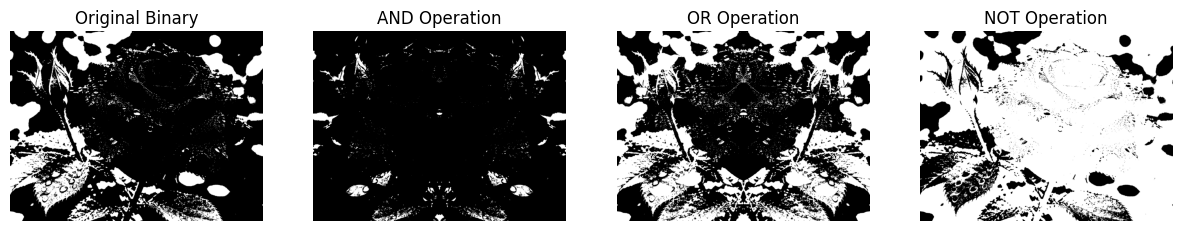

In [6]:
#Perform AND, OR and NOT Operations on an Image
# Convert image into binary image
_, binary = cv2.threshold(
    gray, 127, 255, cv2.THRESH_BINARY
)

# Create second binary image by flipping
binary2 = cv2.flip(binary, 1)

# AND operation
and_img = cv2.bitwise_and(binary, binary2)

# OR operation
or_img = cv2.bitwise_or(binary, binary2)

# NOT operation
not_img = cv2.bitwise_not(binary)

# Display results
plt.figure(figsize=(15,5))

plt.subplot(1,4,1)
plt.imshow(binary, cmap='gray')
plt.title("Original Binary")
plt.axis("off")

plt.subplot(1,4,2)
plt.imshow(and_img, cmap='gray')
plt.title("AND Operation")
plt.axis("off")

plt.subplot(1,4,3)
plt.imshow(or_img, cmap='gray')
plt.title("OR Operation")
plt.axis("off")

plt.subplot(1,4,4)
plt.imshow(not_img, cmap='gray')
plt.title("NOT Operation")
plt.axis("off")

plt.show()

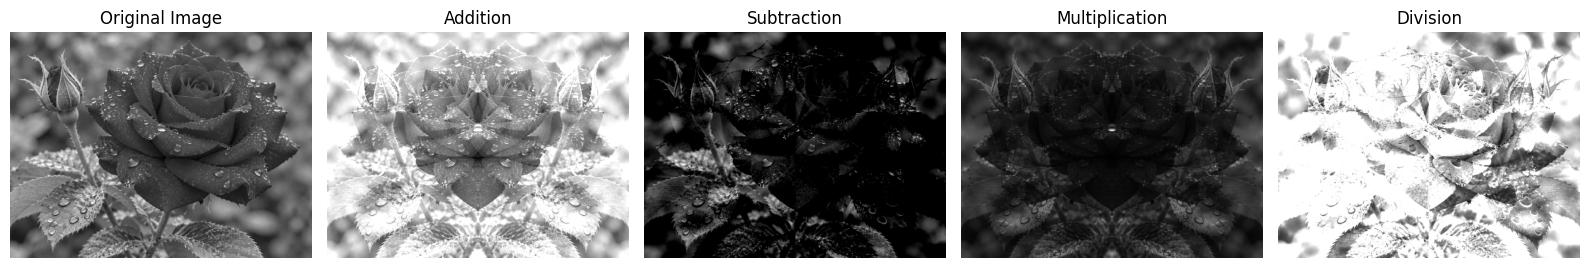

In [7]:
#Perform Four Arithmetic Operations on an Image
# Create second image
img2 = cv2.flip(gray, 1)

# Addition
addition = cv2.add(gray, img2)

# Subtraction
subtraction = cv2.subtract(gray, img2)

# Multiplication
multiplication = np.clip(
    (gray.astype(np.float32) *
     img2.astype(np.float32)) / 255,
    0, 255
).astype(np.uint8)

# Division
division = np.clip(
    (gray.astype(np.float32) /
     (img2.astype(np.float32) + 1)) * 255,
    0, 255
).astype(np.uint8)

# Display results
images = [
    (gray, "Original Image"),
    (addition, "Addition"),
    (subtraction, "Subtraction"),
    (multiplication, "Multiplication"),
    (division, "Division")
]

plt.figure(figsize=(16,6))

for i, (im, title) in enumerate(images):
    plt.subplot(1,5,i+1)
    plt.imshow(im, cmap='gray')
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

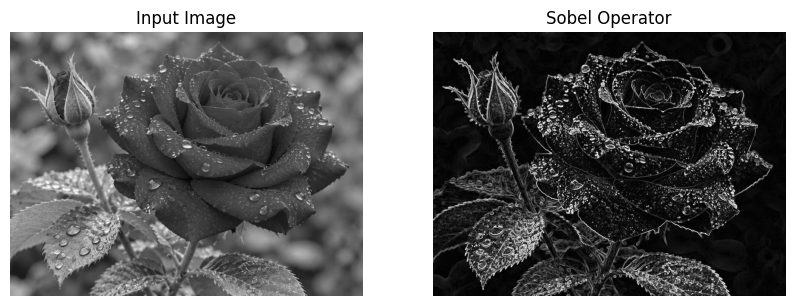

In [8]:
#Apply Different Masks and Filters to a Single Image
#a. Sobel Operator
# Sobel X
sobel_x = cv2.Sobel(
    gray, cv2.CV_64F, 1, 0, ksize=3
)

# Sobel Y
sobel_y = cv2.Sobel(
    gray, cv2.CV_64F, 0, 1, ksize=3
)

# Combine Sobel X and Y
sobel = cv2.magnitude(sobel_x, sobel_y)

sobel = cv2.convertScaleAbs(sobel)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(gray, cmap='gray')
plt.title("Input Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(sobel, cmap='gray')
plt.title("Sobel Operator")
plt.axis("off")

plt.show()

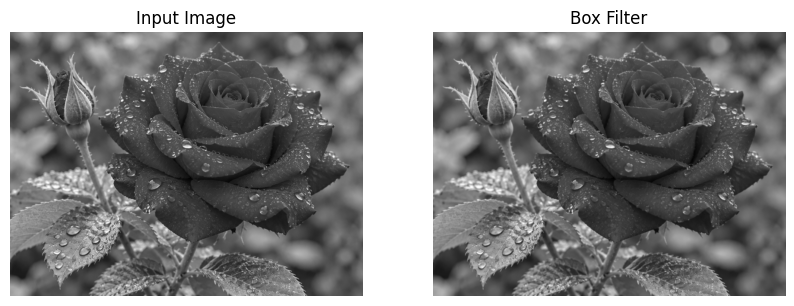

In [9]:
#b. Box Filter
box = cv2.blur(gray, (3,3))

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(gray, cmap='gray')
plt.title("Input Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(box, cmap='gray')
plt.title("Box Filter")
plt.axis("off")

plt.show()

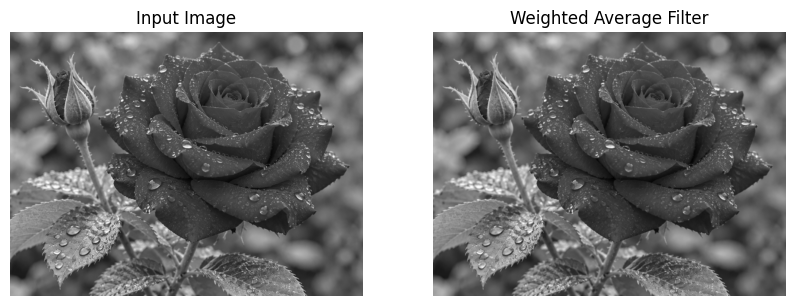

In [10]:
#c. Weighted Average Filter
kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float32) / 16

weighted = cv2.filter2D(gray, -1, kernel)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(gray, cmap='gray')
plt.title("Input Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(weighted, cmap='gray')
plt.title("Weighted Average Filter")
plt.axis("off")

plt.show()

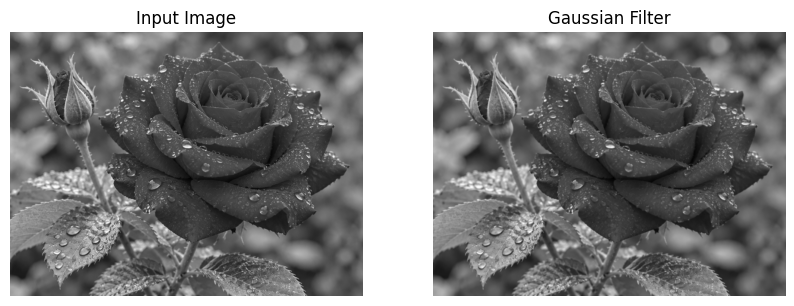

In [11]:
#d. Gaussian Filter Mask
gaussian = cv2.GaussianBlur(gray, (5,5), 0)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(gray, cmap='gray')
plt.title("Input Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(gaussian, cmap='gray')
plt.title("Gaussian Filter")
plt.axis("off")

plt.show()

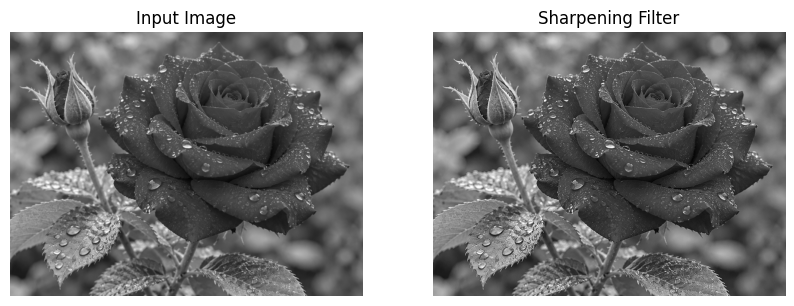

In [12]:
#e. Sharpening Filter
sharpen_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharpen = cv2.filter2D(
    gray, -1, sharpen_kernel
)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(gray, cmap='gray')
plt.title("Input Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(sharpen, cmap='gray')
plt.title("Sharpening Filter")
plt.axis("off")

plt.show()

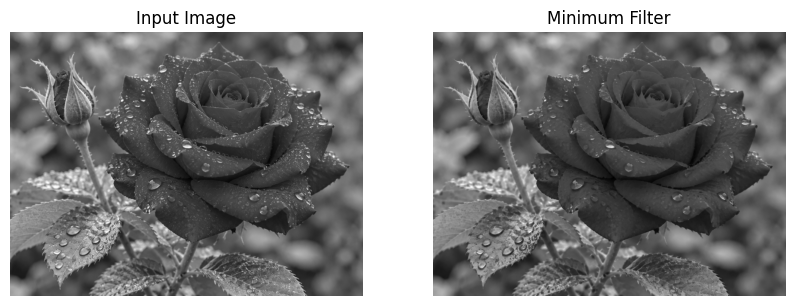

In [13]:
# f. Minimum Filter
minimum = cv2.erode(
    gray, np.ones((3,3), np.uint8)
)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(gray, cmap='gray')
plt.title("Input Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(minimum, cmap='gray')
plt.title("Minimum Filter")
plt.axis("off")

plt.show()

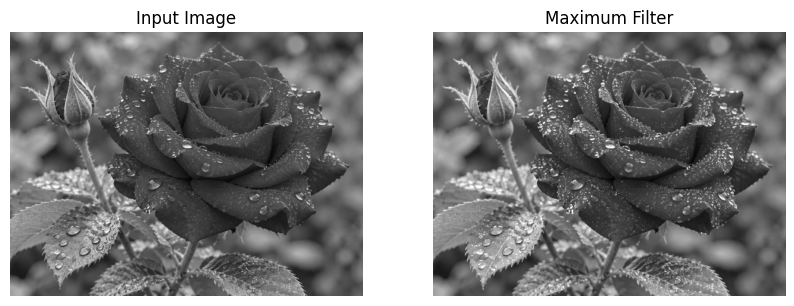

In [14]:
#Maximum Filter
maximum = cv2.dilate(
    gray, np.ones((3,3), np.uint8)
)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(gray, cmap='gray')
plt.title("Input Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(maximum, cmap='gray')
plt.title("Maximum Filter")
plt.axis("off")

plt.show()

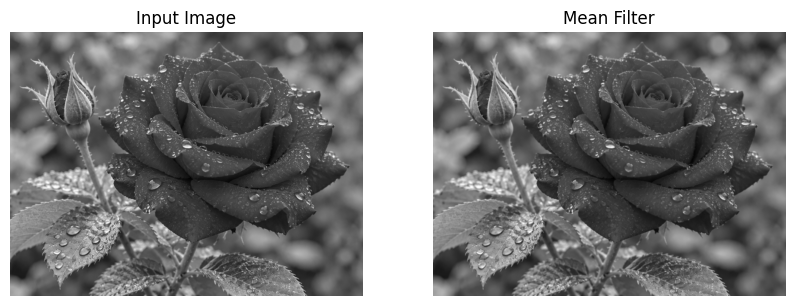

In [15]:
#Mean Filter
mean = cv2.blur(gray, (3,3))

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(gray, cmap='gray')
plt.title("Input Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(mean, cmap='gray')
plt.title("Mean Filter")
plt.axis("off")

plt.show()

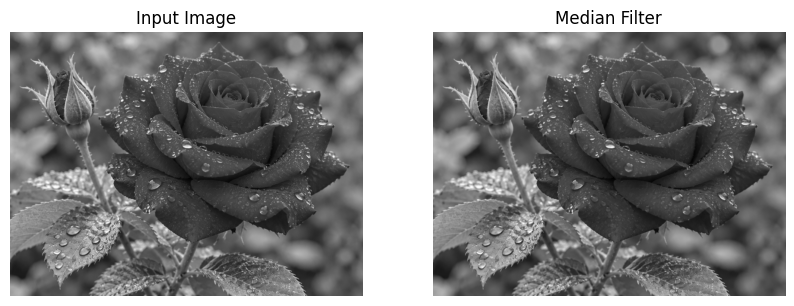

In [16]:
#Median Filter
median = cv2.medianBlur(gray, 3)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(gray, cmap='gray')
plt.title("Input Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(median, cmap='gray')
plt.title("Median Filter")
plt.axis("off")

plt.show()

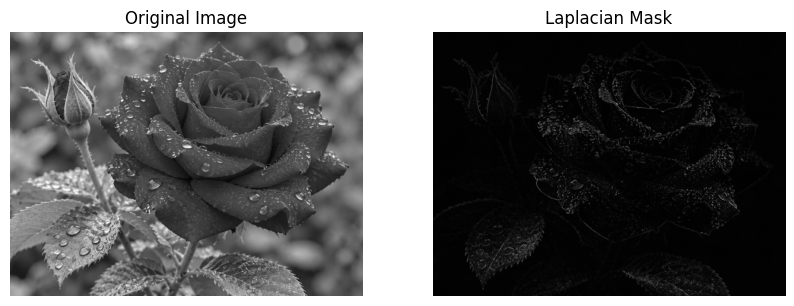

In [17]:
#ask 5: Laplacian, Enhanced Laplacian and High-Boost Mask
#a. Laplacian Mask
laplacian_kernel = np.array([
    [0, 1, 0],
    [1, -4, 1],
    [0, 1, 0]
])

laplacian = cv2.filter2D(
    gray, cv2.CV_32F, laplacian_kernel
)

laplacian = cv2.convertScaleAbs(laplacian)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(gray, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(laplacian, cmap='gray')
plt.title("Laplacian Mask")
plt.axis("off")

plt.show()

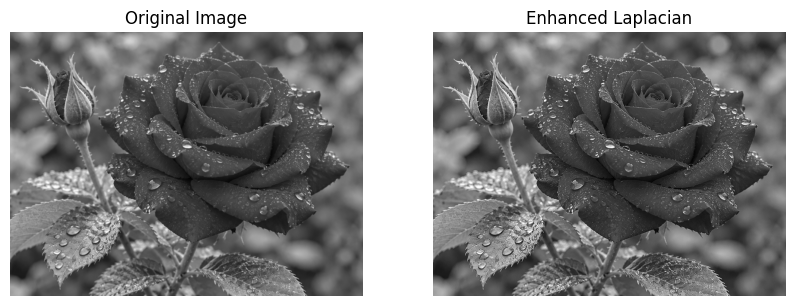

In [18]:
#b. Enhanced Laplacian Mask
laplacian_float = cv2.filter2D(
    gray, cv2.CV_32F, laplacian_kernel
)

enhanced_laplacian = np.clip(
    gray.astype(np.float32) - laplacian_float,
    0, 255
).astype(np.uint8)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(gray, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(enhanced_laplacian, cmap='gray')
plt.title("Enhanced Laplacian")
plt.axis("off")

plt.show()

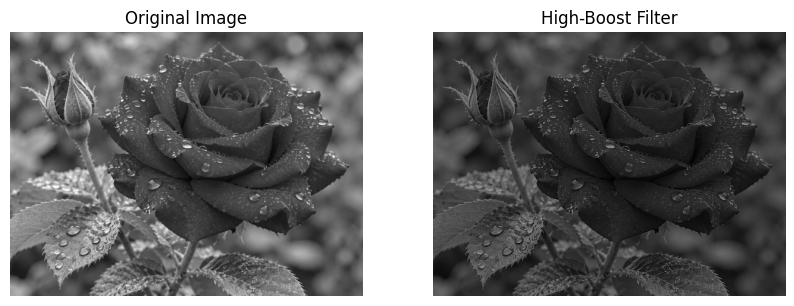

In [19]:
#c. High-Boost Mask
# Apply Gaussian blur
blurred = cv2.GaussianBlur(gray, (5,5), 0)

# High-boost parameter
A = 1.5

# High-boost filtering
high_boost = np.clip(
    A * gray.astype(np.float32) -
    blurred.astype(np.float32),
    0, 255
).astype(np.uint8)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(gray, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(high_boost, cmap='gray')
plt.title("High-Boost Filter")
plt.axis("off")

plt.show()

In [20]:
#Save All Output Images
# Create output folder
os.makedirs("Lab_Results", exist_ok=True)

# Save all outputs
outputs = {
    "Original": gray,
    "Histogram_Equalization": equalized,
    "AND": and_img,
    "OR": or_img,
    "NOT": not_img,
    "Addition": addition,
    "Subtraction": subtraction,
    "Multiplication": multiplication,
    "Division": division,
    "Sobel": sobel,
    "Box_Filter": box,
    "Weighted_Average": weighted,
    "Gaussian": gaussian,
    "Sharpening": sharpen,
    "Minimum": minimum,
    "Maximum": maximum,
    "Mean": mean,
    "Median": median,
    "Laplacian": laplacian,
    "Enhanced_Laplacian": enhanced_laplacian,
    "High_Boost": high_boost
}

for name, image in outputs.items():
    cv2.imwrite(
        f"Lab_Results/{name}.png",
        image
    )

print("All output images saved successfully!")

# Download all results as ZIP
import shutil

shutil.make_archive(
    "Graphics_Lab_Results",
    'zip',
    "Lab_Results"
)

files.download("Graphics_Lab_Results.zip")

All output images saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>